# Chapitre 3 - Cours 3 : LAR, PCR, PLS et comparaison des méthodes

Ce dernier notebook de cours couvre les sections 3.4.4 à 3.6 du livre :

1. la **régression du moindre angle** (LAR, *least angle regression*), son lien avec le
   lasso et ses degrés de liberté (figures 3.14, 3.15) ;
2. les méthodes à **directions dérivées** : régression sur composantes principales (PCR)
   et moindres carrés partiels (PLS) (figure 3.17, algorithme 3.3) ;
3. la **comparaison** de toutes les méthodes du chapitre sur la prostate (figure 3.7
   complète, tableau 3.3) et sur un problème jouet à deux variables (figure 3.18).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

import pandas as pd
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import lars_path
from esl import ch03_regression as cr

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 120)


def show(df):
    """Affiche un tableau arrondi, les coefficients absents (NaN) laissés en blanc."""
    return df.round(3).astype(object).where(df.notna(), "")

In [2]:
Xtr, ytr, Xte, yte, names = cr.load_prostate_standardized()
N, p = Xtr.shape
fit_ls = cr.ols_fit(Xtr, ytr)


def test_error(b0, beta):
    """Erreur quadratique moyenne sur l'échantillon de test."""
    return np.mean((yte - b0 - Xte @ beta) ** 2)

## 1. Régression du moindre angle (LAR)

LAR est une version « démocratique » de la sélection pas à pas ascendante. Au lieu
d'ajouter **entièrement** une variable au modèle, elle n'en ajoute que « la part
méritée » (algorithme 3.2 du livre) :

1. Standardiser les prédicteurs (moyenne nulle, norme 1). Partir de $\mathbf{r} = \mathbf{y} - \bar y$
   et $\beta_1 = \dots = \beta_p = 0$.
2. Trouver le prédicteur $\mathbf{x}_j$ le plus corrélé à $\mathbf{r}$.
3. Faire croître $\beta_j$ de 0 vers son coefficient des moindres carrés
   $\langle\mathbf{x}_j, \mathbf{r}\rangle$, **jusqu'à ce qu'un autre** prédicteur
   $\mathbf{x}_k$ ait autant de corrélation avec le résidu courant.

4. Faire évoluer $\beta_j$ et $\beta_k$ dans la direction de leur coefficient des moindres
   carrés **joint** (régression du résidu sur $(\mathbf{x}_j, \mathbf{x}_k)$), jusqu'à ce
   qu'un troisième prédicteur $\mathbf{x}_l$ rattrape la même corrélation.
5. Continuer ainsi jusqu'à ce que tous les prédicteurs soient entrés. Après
   $\min(N-1, p)$ étapes, on obtient la solution des moindres carrés complète.

**La direction de l'étape $k$.** Notons $\mathcal{A}_k$ l'ensemble **actif** au début de
l'étape $k$, $\mathbf{X}_{\mathcal{A}_k}$ les colonnes correspondantes et
$\mathbf{r}_k = \mathbf{y} - \mathbf{X}_{\mathcal{A}_k}\beta_{\mathcal{A}_k}$ le résidu.
La direction des coefficients est (éq. (3.55))

$$
\delta_k = (\mathbf{X}_{\mathcal{A}_k}^T\mathbf{X}_{\mathcal{A}_k})^{-1}\mathbf{X}_{\mathcal{A}_k}^T\mathbf{r}_k ,
$$

et l'on pose $\beta_{\mathcal{A}_k}(\alpha) = \beta_{\mathcal{A}_k} + \alpha\,\delta_k$. Les
valeurs ajustées évoluent selon $\hat{\mathbf{f}}_k(\alpha) = \hat{\mathbf{f}}_k + \alpha\,\mathbf{u}_k$
avec $\mathbf{u}_k = \mathbf{X}_{\mathcal{A}_k}\delta_k$.

**Pourquoi les corrélations restent à égalité.** Supposons qu'au début de l'étape toutes
les variables actives aient la même corrélation absolue $C$ avec le résidu :
$\mathbf{X}_{\mathcal{A}}^T\mathbf{r}_k = C\,\mathbf{s}$ où $\mathbf{s}$ est le vecteur
des signes. Alors $\mathbf{X}_{\mathcal{A}}^T\mathbf{u}_k = \mathbf{X}_{\mathcal{A}}^T\mathbf{X}_{\mathcal{A}}\delta_k = \mathbf{X}_{\mathcal{A}}^T\mathbf{r}_k = C\,\mathbf{s}$, donc

$$
\mathbf{X}_{\mathcal{A}}^T\bigl(\mathbf{r}_k - \alpha\,\mathbf{u}_k\bigr) = (1 - \alpha)\,C\,\mathbf{s} :
$$

les corrélations actives décroissent **ensemble**, linéairement, et restent égales en
valeur absolue. Comme $\mathbf{u}_k$ fait le même produit scalaire avec chaque
$s_j\mathbf{x}_j$ (de norme 1), il fait **le même angle** avec chacune : c'est l'origine du
nom « moindre angle » (exercice 3.24).

> **Remarque (pas de petits pas).** Les corrélations des variables inactives
> $\langle\mathbf{x}_\ell, \mathbf{r}_k - \alpha\mathbf{u}_k\rangle$ sont aussi affines en
> $\alpha$ : on calcule **exactement** la valeur de $\alpha$ où l'une d'elles rattrape les
> variables actives (exercice 3.25). LAR calcule ainsi tout son chemin en $p$ étapes, pour
> le coût d'une régression par moindres carrés.

### 1.1 Illustration sur données simulées (figure 3.14)

Comme le livre, prenons un jeu simulé à six prédicteurs. On trace la corrélation absolue
$|\langle\mathbf{x}_j, \mathbf{r}\rangle|$ de chaque prédicteur avec le résidu courant, en
fonction de la **longueur d'arc $L_1$** du chemin des coefficients (somme des
$\lVert\Delta\beta\rVert_1$ d'une étape à l'autre).

In [3]:
rng = np.random.RandomState(13)
Ns, ps = 60, 6
Xsim = rng.randn(Ns, ps) @ rng.randn(ps, ps)
ysim = Xsim @ (2 * rng.randn(ps)) + 4 * rng.randn(Ns)
Xsim = Xsim - Xsim.mean(0)
Xsim = Xsim / np.linalg.norm(Xsim, axis=0)          # colonnes de norme 1
ysim = ysim - ysim.mean()
coefs_lar, corr_lar, actions_lar = cr.lars(Xsim, ysim, method="lar")
arc = np.r_[0, np.cumsum(np.abs(np.diff(coefs_lar, axis=0)).sum(1))]
abs_corr = np.abs((ysim[:, None] - Xsim @ coefs_lar.T).T @ Xsim)     # (nœuds, p)
print("ordre d'entrée :", ["x%d" % (j + 1) for j in actions_lar])

ordre d'entrée : ['x6', 'x2', 'x3', 'x4', 'x1', 'x5']


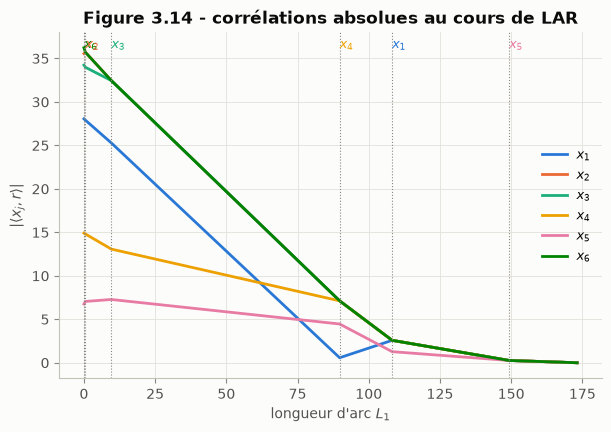

In [4]:
fig, ax = plt.subplots()
for j in range(ps):
    ax.plot(arc, abs_corr[:, j], color=COLORS[j], label="$x_%d$" % (j + 1))
for k, (a_k, j) in enumerate(zip(arc[:-1], actions_lar)):
    ax.axvline(a_k, color=GRAY, linestyle=":", linewidth=0.8)
    ax.text(a_k, ax.get_ylim()[1] * 0.98, "$x_%d$" % (j + 1), color=COLORS[j], ha="left", va="top", fontsize=9)
ax.set_title("Figure 3.14 - corrélations absolues au cours de LAR")
ax.set_xlabel("longueur d'arc $L_1$"); ax.set_ylabel(r"$|\langle x_j, r\rangle|$")
ax.legend(loc="center right")
plt.show()

Chaque variable qui entre rejoint la courbe commune des corrélations maximales, qui décroît
par morceaux linéaires jusqu'à 0 (solution des moindres carrés, où le résidu est orthogonal
à toutes les entrées). Vérifions l'égalité des angles à une étape intermédiaire :

In [5]:
k = 3
r_k = ysim - Xsim @ coefs_lar[k]
delta = coefs_lar[k + 1] - coefs_lar[k]
u = Xsim @ delta
active = [j for j in actions_lar[:k + 1]]
cos = Xsim[:, active].T @ u / np.linalg.norm(u)
print("variables actives :", ["x%d" % (j + 1) for j in active])
print("corrélations avec le résidu :", (Xsim[:, active].T @ r_k).round(4))
print("cosinus des angles (x_j, u_k) :", cos.round(4))

variables actives : ['x6', 'x2', 'x3', 'x4']
corrélations avec le résidu : [ 7.1213  7.1213  7.1213 -7.1213]
cosinus des angles (x_j, u_k) : [ 0.4963  0.4963  0.4963 -0.4963]


### 1.2 LAR et lasso (algorithme 3.2a, figure 3.15)

Les chemins de LAR et du lasso sont souvent **identiques**. Ils diffèrent seulement
lorsqu'un coefficient non nul **traverse zéro**. La modification qui rend LAR exactement
égal au lasso est :

> **4a.** Si un coefficient non nul atteint zéro, retirer sa variable de l'ensemble actif et
> recalculer la direction des moindres carrés joints.

*Explication.* Pour le lasso (pénalité $\lambda\lVert\beta\rVert_1$, critère
$\frac12\lVert\mathbf{y} - \mathbf{X}\beta\rVert^2$), les conditions d'optimalité
(éq. (3.58)–(3.59)) imposent, pour chaque variable active,
$\langle\mathbf{x}_j, \mathbf{y} - \mathbf{X}\beta\rangle = \lambda\cdot\mathrm{signe}(\beta_j)$ :
la corrélation doit avoir **le même signe** que le coefficient. LAR impose seulement
$|\langle\mathbf{x}_j, \mathbf{r}\rangle| = \gamma$ commun ; si un $\beta_j$ change de signe
sans que sa corrélation change, la condition du lasso est violée, d'où la règle 4a.

In [6]:
coefs_lasso, _, actions_lasso = cr.lars(Xsim, ysim, method="lasso")
arc_lasso = np.r_[0, np.cumsum(np.abs(np.diff(coefs_lasso, axis=0)).sum(1))]
print("actions LAR   :", ["+x%d" % (j + 1) for j in actions_lar])
print("actions lasso :", ["+x%d" % (j + 1) if j >= 0 else "-x%d" % (-j) for j in actions_lasso])

actions LAR   : ['+x6', '+x2', '+x3', '+x4', '+x1', '+x5']
actions lasso : ['+x6', '+x2', '+x3', '+x4', '+x1', '-x4', '+x5', '+x4']
